In [35]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import torch.optim as optim
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

## Data Loading

In [3]:
IMG_SIZE = 224
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [8]:
train_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Train', transform=train_transforms)
val_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Validation', transform=val_transforms)
test_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Test', transform=val_transforms)

In [11]:
classes = train_dataset.classes

In [14]:
len(train_dataset), len(val_dataset), len(test_dataset)

(140002, 39428, 10905)

In [15]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [17]:
len(train_loader), len(val_loader), len(test_loader)

(4376, 1233, 341)

In [20]:
img, label = train_dataset[0]

In [22]:
img.shape

torch.Size([3, 224, 224])

In [24]:
label

0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.64].


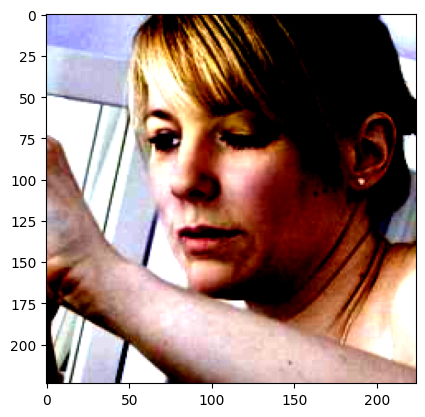

In [23]:
import matplotlib.pyplot as plt

plt.imshow(img.permute(1, 2, 0))

## Model Building

In [42]:
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA Available: True
CUDA Version: 13.0
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [26]:
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\madhu/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 19.0MB/s]


In [27]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [28]:
model.classifier[1] = nn.Linear(in_features=model.classifier[1].in_features, out_features=len(classes))

In [29]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [30]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [40]:
device

device(type='cuda')

In [31]:
print(next(model.parameters()).device)

cuda:0


In [32]:
for param in model.features.parameters():
    param.requires_grad = True

In [34]:
print(model.classifier[1].weight.requires_grad)
print(next(model.features.parameters()).requires_grad)

True
True


In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [43]:
for epoch in range(5):
    current_loss = 0.0
    train_correct = 0
    model.train()
    model.features.eval()
    for i, (images, labels) in enumerate(train_loader):
        if i%100 == 0:
            print(f'Batch {i+1}/{len(train_loader)}')
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        predicted = torch.argmax(outputs, dim=1)
        loss.backward()
        optimizer.step()
        current_loss += loss.item()
        train_correct += (predicted == labels).sum().item()
    print(f'Epoch: {epoch+1}, Loss: {current_loss/len(train_loader)}, Accuracy: {100 * train_correct / len(train_loader.dataset)}%')

    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item()
            predicted = torch.argmax(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Validation Loss: {val_loss/len(val_loader)}, Accuracy: {100 * correct / total}%')

Batch 1/4376
Batch 101/4376


KeyboardInterrupt: 